<a href="https://colab.research.google.com/github/Innej3/SignalPropagation-/blob/main/Retroduction_temporal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
'''
Also paper replication:
But this time only for SIS dynamics

ALong with a retroduction example where we are tring to answer hte question
If someone poked ONE unknown node j. We don't see j.
We only see the arrival times T(j -> o) at a few observer nodes o, plus noise,
and we don't know exactly when the poke happened (unknown onset t0).
Question: which node was the source?

Recipe: for every candidate source s, a predictor D(s, o) says how "far in time"
each observer is from s. If s is the true source, the observed times should line up as
    t_o  ~  t0 + c * D(s, o)      (unknown t0, unknown c > 0)
Fit t0, c by least squares for each candidate, score by the residual, rank candidates.

'''

In [1]:
import networkx as nx
import numpy as np
from scipy.integrate import solve_ivp
from scipy.sparse import csr_matrix
from scipy.stats import gaussian_kde
import matplotlib.pyplot as plt

In [2]:
N = 400
AVG_DEG = 4 #k
B=1.0 # recovery rate
ALPHA = 0.1
ETA = 0.7 #response threshold eta0.7 # used in the paper
NUM_SOURCES = 25
SEED=42
np.random.seed(SEED)

In [3]:
def build_networks(n, k):
  networks = {}
  graphs = {}
  # ER
  G_er = nx.erdos_renyi_graph(n, k/(n-1), seed=SEED)
  largest_cc = max(nx.connected_components(G_er), key=len)
  G_er = nx.convert_node_labels_to_integers(G_er.subgraph(largest_cc))
  networks['ER'] = nx.to_scipy_sparse_array(G_er, dtype=float, format='csr')
  graphs['ER'] = G_er
  # SF - Barabasi-Albert m=2
  G_sf = nx.barabasi_albert_graph(n, m=k//2, seed=SEED)
  largest_cc = max(nx.connected_components(G_sf), key=len)
  A_sf = nx.to_scipy_sparse_array(G_sf, dtype=float, format='csr')
  networks['SF'] = A_sf
  graphs['SF'] = G_sf
  # weighted Scale-Free - U(0.1, 0.9)
  G_sf1 = G_sf.copy()
  for u, v in G_sf1.edges():
    w = np.random.uniform(0.1, 0.9)
    G_sf1[u][v]['weight'] = w
  networks['SF1'] = nx.to_scipy_sparse_array(G_sf1,weight='weight', dtype=float, format='csr')
  graphs['SF1'] = G_sf1

  return networks, graphs


In [4]:
def find_steady_state(A, b=1.0):
  '''
  Steady state of dx_i/dt = -b*x_i + (1-x_i) * sum_j A_ij x_j
  '''
  n = A.shape[0]
  x = np.full(n, 0.5)
  # x_i = (A x)_i / (b + (A x)_i)
  for _ in range(5000):
    Ax = A.dot(x)
    x_next = Ax/ (b+Ax)
    if np.max(np.abs(x_next - x)/ (x_next + 1e-15)) < 1e-13:
      break
    x = x_next
  return x

In [40]:
def perturb_and_measure(A, x_ss, source_j, alpha=0.1, eta=0.7, b=1.0):
  """
  Perturbs node `source_j` permanently by +alpha * x_ss[source_j]
  and measures T(j -> i) when f_ij(t) = (x_i(t) - x_i*) / (x_i(inf) - x_i*) = eta.
  """
  n = A.shape[0]

  x_inf = x_ss.copy()
  x_inf[source_j] = x_ss[source_j] * (1.0 + alpha)

  for _ in range(5000):
    Ax = A.dot(x_inf)
    x_next = Ax/ (b+Ax)
    x_next[source_j] = x_ss[source_j] * (1.0 + alpha)
    if np.max(np.abs(x_next-x_inf) / (x_next +1e-15)) < 1e-13:
      break
    x_inf = x_next
  delta_x_inf = x_inf - x_ss

  y0 = x_ss.copy()
  y0[source_j] = x_ss[source_j] * (1.0 + alpha)

  def sis_code(t, x):
    dx = -b*x + (1.0 - x) * A.dot(x)
    dx[source_j] = 0.0
    return dx
  # logarithmic spaced points rom 10^3 to 15
  t_eval = np.geomspace(1e-3, 15.0, 600)
  sol = solve_ivp(sis_code, [0.0, 15.0], y0, method='RK45', t_eval=t_eval, rtol=1e-9, atol=1e-11)

  # f_ij(t) = Delta x_ij(t) / Delta x_ij(inf)
  T_ji = np.full(n, np.nan)
  for i in range(n):
    if i == source_j or delta_x_inf[i] <= 1e-12:
      continue
    f_i = (sol.y[i, :] - x_ss[i]) / delta_x_inf[i]
    idx = int(np.argmax(f_i >= eta))
    if idx > 0 and f_i[idx] >= eta:
      t0, t1 = t_eval[idx-1], t_eval[idx]
      f0, f1 = f_i[idx-1], f_i[idx]
      T_ji[i] = t0 + (eta - f0) * (t1-t0) / (f1-f0+1e-15)
  return T_ji


In [41]:
def log_binning(S, tau, num_bins=12):
  valid = (~np.isnan(tau)) & (tau > 0) & (S > 0)
  S_val, tau_val = S[valid], tau[valid]
  bins = np.geomspace(S_val.min() * 0.99, S_val.max() * 1.01, num_bins + 1)
  S_binned, tau_binned = [], []
  for k in range(num_bins):
    mask = (S_val > bins[k]) & (S_val <= bins[k+1])
    if np.sum(mask) > 0:
      S_binned.append(np.mean(S_val[mask]))
      tau_binned.append(np.mean(tau_val[mask]))
  return np.array(S_binned), np.array(tau_binned)

In [42]:
networks, graphs = build_networks(N, AVG_DEG)
G_er, G_sf = graphs['ER'], graphs['SF']

In [43]:
results = {}
for name, A in networks.items():
  print(f" -> Solving {name} topology...")
  n_nodes = A.shape[0]
  S = np.array(A.sum(axis=1)).flatten()
  x_ss = find_steady_state(A, B)

  # Pick random source nodes to perturb, plus high-degree nodes so neighbor stats are well-sampled
  sources = np.random.choice(n_nodes, size=min(NUM_SOURCES, n_nodes), replace=False)

  all_T_matrices = {}
  local_neighbor_times = [[] for _ in range(n_nodes)]

  for j in sources:
    T_ji = perturb_and_measure(A, x_ss, j, ALPHA, ETA, B)
    all_T_matrices[j] = T_ji

    # Record direct neighbor response times for local tau_i
    neighbors_of_j = A.indices[A.indptr[j]:A.indptr[j+1]]
    for i in neighbors_of_j:
      if not np.isnan(T_ji[i]):
        local_neighbor_times[i].append(T_ji[i])

  tau_i = np.array([np.mean(times) if len(times) > 0 else np.nan for times in local_neighbor_times])
  results[name] = {'S': S, 'tau': tau_i, 'T_dict': all_T_matrices}

 -> Solving ER topology...
 -> Solving SF topology...
 -> Solving SF1 topology...


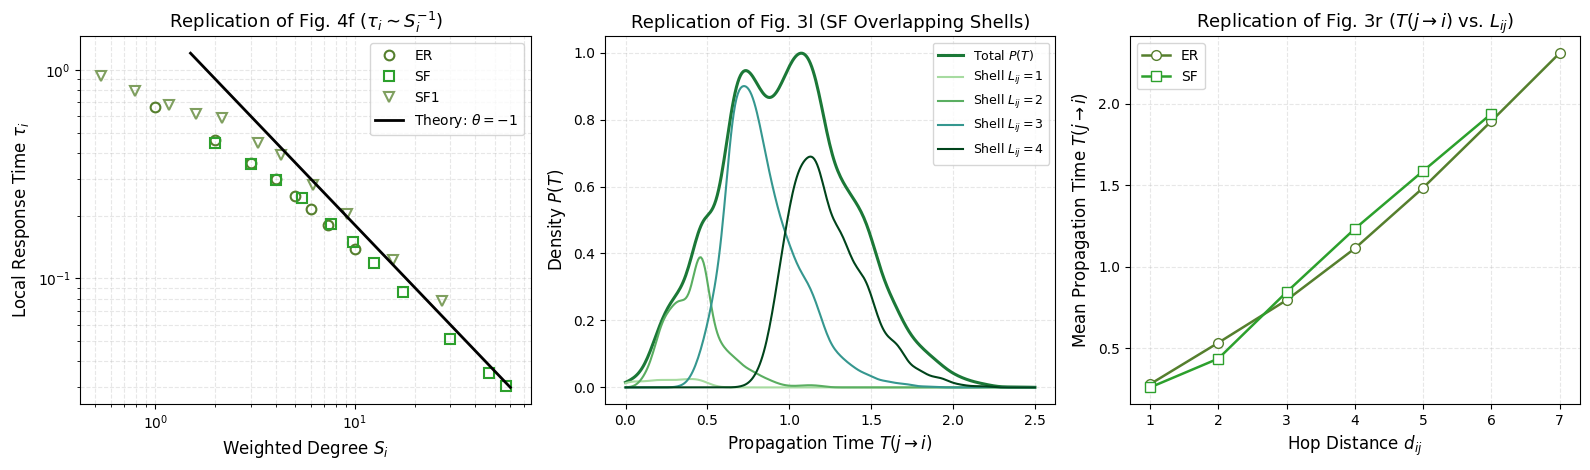

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# --- Panel A: Fig 4f (tau_i vs S_i showing universal slope theta = -1) ---
ax = axes[0]
markers = {'ER': 'o', 'SF': 's', 'SF1': 'v'}
colors = {'ER': '#557f2d', 'SF': '#2ca02c', 'SF1': '#7f9f5f'}

for name in ['ER', 'SF', 'SF1']:
    S_bin, tau_bin = log_binning(results[name]['S'], results[name]['tau'], num_bins=12)
    ax.loglog(S_bin, tau_bin, marker=markers[name], linestyle='None',
              color=colors[name], markersize=7, label=name, markerfacecolor='none', markeredgewidth=1.5)

# Plot analytical reference line tau ~ S^(-1)
s_ref = np.geomspace(1.5, 60, 50)
ax.loglog(s_ref, 1.8 * (s_ref ** -1.0), 'k-', linewidth=2, label=r'Theory: $\theta = -1$')
ax.set_xlabel(r'Weighted Degree $S_i$', fontsize=12)
ax.set_ylabel(r'Local Response Time $\tau_i$', fontsize=12)
ax.set_title(r'Replication of Fig. 4f ($\tau_i \sim S_i^{-1}$)', fontsize=13)
ax.legend()
ax.grid(True, which="both", ls="--", alpha=0.3)

# --- Panel B: Fig 3l (P(T) and P(T | L_ij) on Scale-Free Network) ---
ax = axes[1]
T_all_sf = []
T_by_dist_sf = {1: [], 2: [], 3: [], 4: []}

for j, T_ji in results['SF']['T_dict'].items():
    lengths = nx.single_source_shortest_path_length(G_sf, j)
    for i, dist in lengths.items():
        if dist >= 1 and not np.isnan(T_ji[i]):
            T_all_sf.append(T_ji[i])
            if dist in T_by_dist_sf:
                T_by_dist_sf[dist].append(T_ji[i])

t_grid = np.linspace(0, 2.5, 300)
kde_total = gaussian_kde(T_all_sf)
ax.plot(t_grid, kde_total(t_grid), color='#1b7837', lw=2.2, label='Total $P(T)$')

shell_colors = ['#a6dba0', '#5aae61', '#35978f', '#00441b']
for idx, d in enumerate([1, 2, 3, 4]):
  if len(T_by_dist_sf[d]) > 10:
    kde_d = gaussian_kde(T_by_dist_sf[d])
    frac = len(T_by_dist_sf[d]) / len(T_all_sf)
    ax.plot(t_grid, frac * kde_d(t_grid), color=shell_colors[idx], lw=1.5, label=f'Shell $L_{{ij}}={d}$')

ax.set_xlabel(r'Propagation Time $T(j \rightarrow i)$', fontsize=12)
ax.set_ylabel(r'Density $P(T)$', fontsize=12)
ax.set_title('Replication of Fig. 3l (SF Overlapping Shells)', fontsize=13)
ax.legend(fontsize=9)
ax.grid(True, ls="--", alpha=0.3)

# --- Panel C: Fig 3r (T(j -> i) vs Shortest Path Distance L_ij) ---
ax = axes[2]
for name, G_graph, marker in [('ER', G_er, 'o'), ('SF', G_sf, 's')]:
  dist_map = {}
  for j, T_ji in results[name]['T_dict'].items():
    lengths = nx.single_source_shortest_path_length(G_graph, j)
    for i, d in lengths.items():
      if d >= 1 and not np.isnan(T_ji[i]):
        dist_map.setdefault(d, []).append(T_ji[i])
  dists = sorted([d for d in dist_map.keys() if len(dist_map[d]) > 15 and d <= 7])
  mean_T = [np.mean(dist_map[d]) for d in dists]
  ax.plot(dists, mean_T, marker=marker, lw=1.8, color=colors[name],
            markerfacecolor='white', markersize=7, label=name)

ax.set_xlabel(r'Hop Distance $d_{ij}$', fontsize=12)
ax.set_ylabel(r'Mean Propagation Time $T(j \rightarrow i)$', fontsize=12)
ax.set_title(r'Replication of Fig. 3r ($T(j \rightarrow i)$ vs. $L_{ij}$)', fontsize=13)
ax.legend()
ax.grid(True, ls="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [45]:
from collections import deque

In [46]:
def compute_temporal_distance(G, S, source_j, theta=-1.0):
  """
  Computes L(j -> i) = min_{Pi(j -> i)} sum_{p in Pi(j -> i)} S_p^theta
  """
  n = len(S)
  node_weights = S ** theta

  dist_hops = np.full(n, np.inf)
  L_ji = np.full(n, np.inf)

  dist_hops[source_j] = 0
  L_ji[source_j] = 0.0
  queue = deque([source_j])

  while queue:
    u = queue.popleft()
    for v in G.neighbors(u):
      if dist_hops[v] == np.inf:
        dist_hops[v] = dist_hops[u] + 1
        L_ji[v] = L_ji[u] + node_weights[v]
        queue.append(v)

      elif dist_hops[v] == dist_hops[u] + 1:
        if L_ji[u] + node_weights[v] < L_ji[v]:
          L_ji[v] = L_ji[u] + node_weights[v]
  L_ji[source_j] = np.nan
  return L_ji

In [47]:
def perturb_and_measure(A, x_ss, source_j, alpha=0.1, eta=0.7, b=1.0, return_snapshot_t=None):
    n = A.shape[0]
    x_inf = x_ss.copy()
    x_inf[source_j] = x_ss[source_j] * (1.0 + alpha)
    for _ in range(5000):
        Ax = A.dot(x_inf)
        x_next = Ax / (b + Ax)
        x_next[source_j] = x_ss[source_j] * (1.0 + alpha)
        if np.max(np.abs(x_next - x_inf) / (x_next + 1e-15)) < 1e-13:
            break
        x_inf = x_next

    delta_x_inf = x_inf - x_ss
    y0 = x_ss.copy()
    y0[source_j] = x_ss[source_j] * (1.0 + alpha)

    def sis_ode(t, x):
        dx = -b * x + (1.0 - x) * A.dot(x)
        dx[source_j] = 0.0
        return dx

    t_eval = np.geomspace(1e-3, 15.0, 600)
    if return_snapshot_t is not None and return_snapshot_t not in t_eval:
        t_eval = np.sort(np.append(t_eval, return_snapshot_t))

    sol = solve_ivp(sis_ode, [0.0, 15.0], y0, method='RK45', t_eval=t_eval, rtol=1e-9, atol=1e-11)

    T_ji = np.full(n, np.nan)
    snapshot_f = np.zeros(n)
    snap_idx = np.searchsorted(t_eval, return_snapshot_t) if return_snapshot_t is not None else 0

    for i in range(n):
        if i == source_j:
            snapshot_f[i] = 1.0
            continue
        if delta_x_inf[i] <= 1e-12:
            continue
        f_i = (sol.y[i, :] - x_ss[i]) / delta_x_inf[i]
        if return_snapshot_t is not None:
            snapshot_f[i] = np.clip(f_i[snap_idx], 0.0, 1.0)
        idx = np.searchsorted(f_i, eta)
        if 0 < idx < len(t_eval):
            t0, t1 = t_eval[idx - 1], t_eval[idx]
            f0, f1 = f_i[idx - 1], f_i[idx]
            T_ji[i] = t0 + (eta - f0) * (t1 - t0) / (f1 - f0 + 1e-15)

    return (T_ji, snapshot_f) if return_snapshot_t is not None else T_ji

In [48]:
THETA = -1.0

In [49]:
networks, graphs = build_networks(N, AVG_DEG)
metric_data = {}

for name in ['ER', 'SF', 'SF1']:
    A = networks[name]
    G = graphs[name]
    S = np.array(A.sum(axis=1)).flatten()
    x_ss = find_steady_state(A, B)

    sources = np.random.choice(A.shape[0], size=NUM_SOURCES, replace=False)
    inv_L_all, inv_T_all = [], []

    for j in sources:
        T_ji = perturb_and_measure(A, x_ss, j, ALPHA, ETA, B)
        L_ji = compute_temporal_distance(G, S, j, theta=THETA)

        valid = (~np.isnan(T_ji)) & (~np.isnan(L_ji)) & (T_ji > 0) & (L_ji > 0)
        inv_L_all.extend(1.0 / L_ji[valid])
        inv_T_all.extend(1.0 / T_ji[valid])

    metric_data[name] = (np.array(inv_L_all), np.array(inv_T_all))

In [50]:
A_sf = networks['SF']
G_sf = graphs['SF']
S_sf = np.array(A_sf.sum(axis=1)).flatten()
x_ss_sf = find_steady_state(A_sf, B)

In [51]:
source_demo = int(np.argsort(S_sf)[len(S_sf)//2])
T_demo, f_snapshot = perturb_and_measure(A_sf, x_ss_sf, source_demo, ALPHA, ETA, B, return_snapshot_t=0.45)
L_demo = compute_temporal_distance(G_sf, S_sf, source_demo, theta=THETA)
L_demo[source_demo] = 0.0

In [52]:
hop_lengths = nx.single_source_shortest_path_length(G_sf, source_demo)
angles = np.random.uniform(0, 2 * np.pi, size=len(S_sf))
r_topo = np.array([hop_lengths[i] + np.random.uniform(-0.35, 0.35) for i in range(len(S_sf))])
r_topo[source_demo] = 0.0

In [53]:
r_dynamic = L_demo.copy()

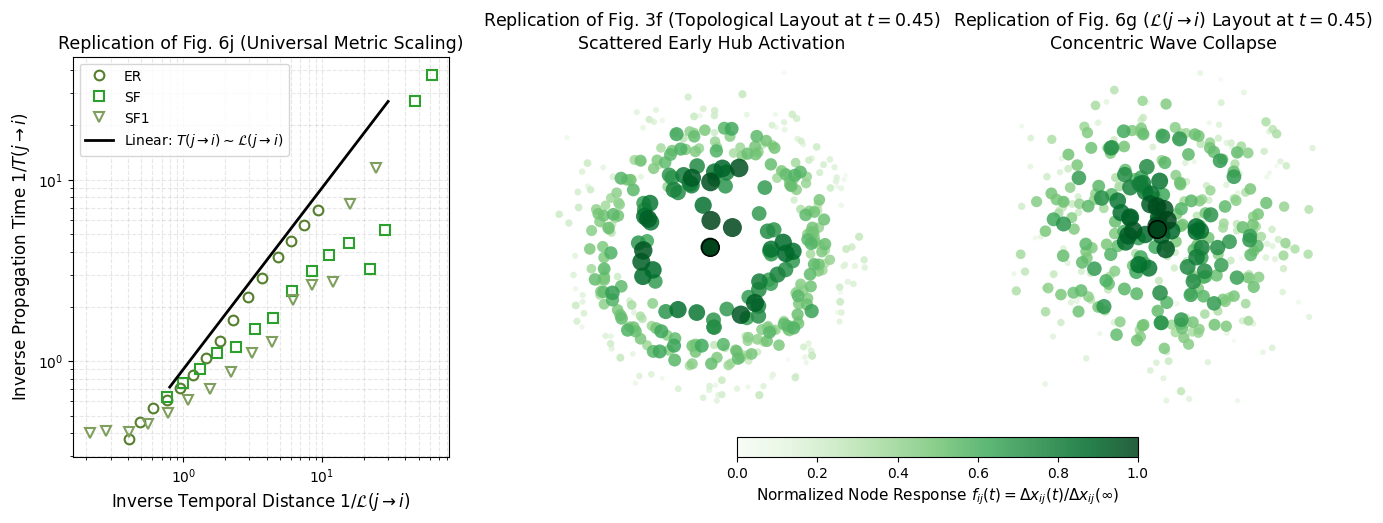

In [54]:
fig, axes = plt.subplots(1, 3, figsize=(16.5, 5.2))

# --- Panel 1: Replication of Fig. 6j (1/T(j->i) vs 1/L(j->i)) ---
ax = axes[0]
markers = {'ER': 'o', 'SF': 's', 'SF1': 'v'}
colors = {'ER': '#557f2d', 'SF': '#2ca02c', 'SF1': '#7f9f5f'}

for name in ['ER', 'SF', 'SF1']:
    inv_L, inv_T = metric_data[name]
    xb, yb = log_binning(inv_L, inv_T, num_bins=15)
    ax.loglog(xb, yb, marker=markers[name], linestyle='None', color=colors[name],
              markersize=7, markerfacecolor='none', markeredgewidth=1.5, label=name)

# Linear reference line (slope = 1 on log-log axes)
x_ref = np.geomspace(0.8, 30, 50)
ax.loglog(x_ref, 0.9 * x_ref, 'k-', lw=2, label=r'Linear: $T(j\rightarrow i) \sim \mathcal{L}(j\rightarrow i)$')
ax.set_xlabel(r'Inverse Temporal Distance $1 / \mathcal{L}(j \rightarrow i)$', fontsize=12)
ax.set_ylabel(r'Inverse Propagation Time $1 / T(j \rightarrow i)$', fontsize=12)
ax.set_title('Replication of Fig. 6j (Universal Metric Scaling)', fontsize=12.5)
ax.legend()
ax.grid(True, which="both", ls="--", alpha=0.3)

# Helper function to draw network snapshots (size & color depth proportional to f_ij(t))
def draw_snapshot(ax, radii, angles, f_vals, source_idx, title):
    x_coords = radii * np.cos(angles)
    y_coords = radii * np.sin(angles)

    # Sort so highly activated nodes are plotted on top
    order = np.argsort(f_vals)
    sizes = 10 + 180 * (f_vals[order] ** 1.5)

    scatter = ax.scatter(x_coords[order], y_coords[order], s=sizes, c=f_vals[order],
                         cmap='Greens', vmin=0.0, vmax=1.0, alpha=0.85, edgecolors='none')
    ax.scatter([0], [0], s=160, c='#00441b', edgecolors='black', zorder=10, label='Source $j$')
    ax.set_title(title, fontsize=12.5)
    ax.set_aspect('equal')
    ax.axis('off')
    return scatter

# --- Panel 2: Standard Layout (Replication of Fig. 3f middle snapshot) ---
draw_snapshot(axes[1], r_topo, angles, f_snapshot, source_demo,
              'Replication of Fig. 3f (Topological Layout at $t=0.45$)\nScattered Early Hub Activation')

# --- Panel 3: Universal Metric Layout (Replication of Fig. 6g middle snapshot) ---
sc = draw_snapshot(axes[2], r_dynamic, angles, f_snapshot, source_demo,
                   r'Replication of Fig. 6g ($\mathcal{L}(j\rightarrow i)$ Layout at $t=0.45$)' + '\nConcentric Wave Collapse')

cbar = fig.colorbar(sc, ax=axes[1:], orientation='horizontal', fraction=0.05, pad=0.05)
cbar.set_label(r'Normalized Node Response $f_{ij}(t) = \Delta x_{ij}(t) / \Delta x_{ij}(\infty)$', fontsize=11)

plt.show()

In [55]:
def predictor_matrices(A, G, x_ss):
  n = A.shape[0]
  S = np.asarray(A.sum(axis=1)).ravel()
  J = B + A.dot(x_ss)                                   # exact |J_ii| for SIS
  D = {k: np.zeros((n, n)) for k in ['hops', 'L_S', 'L_J', 'oracle']}
  for s in range(n):
    D['hops'][s] = compute_temporal_distance(G, S, s, theta=0.0)
    D['L_S'][s]  = compute_temporal_distance(G, S, s, theta=-1.0)
    D['L_J'][s]  = compute_temporal_distance(G, J, s, theta=-1.0)
    D['oracle'][s] = perturb_and_measure(A, x_ss, s, ALPHA, ETA, B)
    for k in D:
      D[k][s, s] = 0.0                             # a candidate is at distance 0 from itself
  return D


In [56]:
retro = {}
for name in ['ER', 'SF']:
  A, G = networks[name], graphs[name]
  x_ss = find_steady_state(A, B)
  print(f"precomputing {name} (simulates every node as a source, ~30 s)...")
  retro[name] = predictor_matrices(A, G, x_ss)


precomputing ER (simulates every node as a source, ~30 s)...
precomputing SF (simulates every node as a source, ~30 s)...


In [57]:
def rank_candidates(t_obs, obs, Dmat):
  """Return candidate sources sorted best-first, fitting t_o = t0 + c*D(s,o), c > 0."""
  Dk = Dmat[:, obs]                                     # (n_candidates, n_obs)
  ok = np.all(np.isfinite(Dk), axis=1)
  score = np.full(Dk.shape[0], np.inf)
  t = t_obs - t_obs.mean()
  Dc = Dk[ok] - Dk[ok].mean(axis=1, keepdims=True)
  var = (Dc ** 2).sum(axis=1)
  c = np.where(var > 0, (Dc @ t) / np.maximum(var, 1e-30), 0.0)
  rss = ((t[None, :] - c[:, None] * Dc) ** 2).sum(axis=1)
  rss[c <= 0] = np.inf                                  # signal must travel outward
  score[ok] = rss
  return np.argsort(score)


In [58]:
def run_retrodiction(name, obs_frac, noise, n_trials=150, seed=0):
  rng = np.random.default_rng(seed)
  D = retro[name]; n = D['hops'].shape[0]
  T_true = D['oracle']; hops = D['hops']
  k_obs = max(3, int(round(obs_frac * n)))
  out = {k: {'top1': [], 'top5': [], 'err_hops': []} for k in D}
  for _ in range(n_trials):
    obs = rng.choice(n, k_obs, replace=False)
    j = rng.choice(np.setdiff1d(np.arange(n), obs))   # true source is never an observer
    t_obs = T_true[j, obs].copy()
    if not np.all(np.isfinite(t_obs)):
        continue
    t_obs *= np.exp(noise * rng.standard_normal(k_obs))   # multiplicative timing noise
    t_obs += rng.uniform(0, 5)                            # unknown onset time
    for k in D:
      # oracle with zero noise is trivially perfect; it still has to beat the noise
      order = rank_candidates(t_obs, obs, D[k])
      out[k]['top1'].append(order[0] == j)
      out[k]['top5'].append(j in order[:5])
      out[k]['err_hops'].append(hops[j, order[0]])
  return {k: {m: float(np.mean(v)) for m, v in d.items()} for k, d in out.items()}


In [59]:
obs_fracs = [0.02, 0.05, 0.10, 0.20]
noises = [0.0, 0.2]
preds = ['hops', 'L_S', 'L_J', 'oracle']
pcol = {'hops': '#888888', 'L_S': '#2ca02c', 'L_J': '#1f77b4', 'oracle': 'k'}
pls = {'hops': '-', 'L_S': '-', 'L_J': '-', 'oracle': '--'}

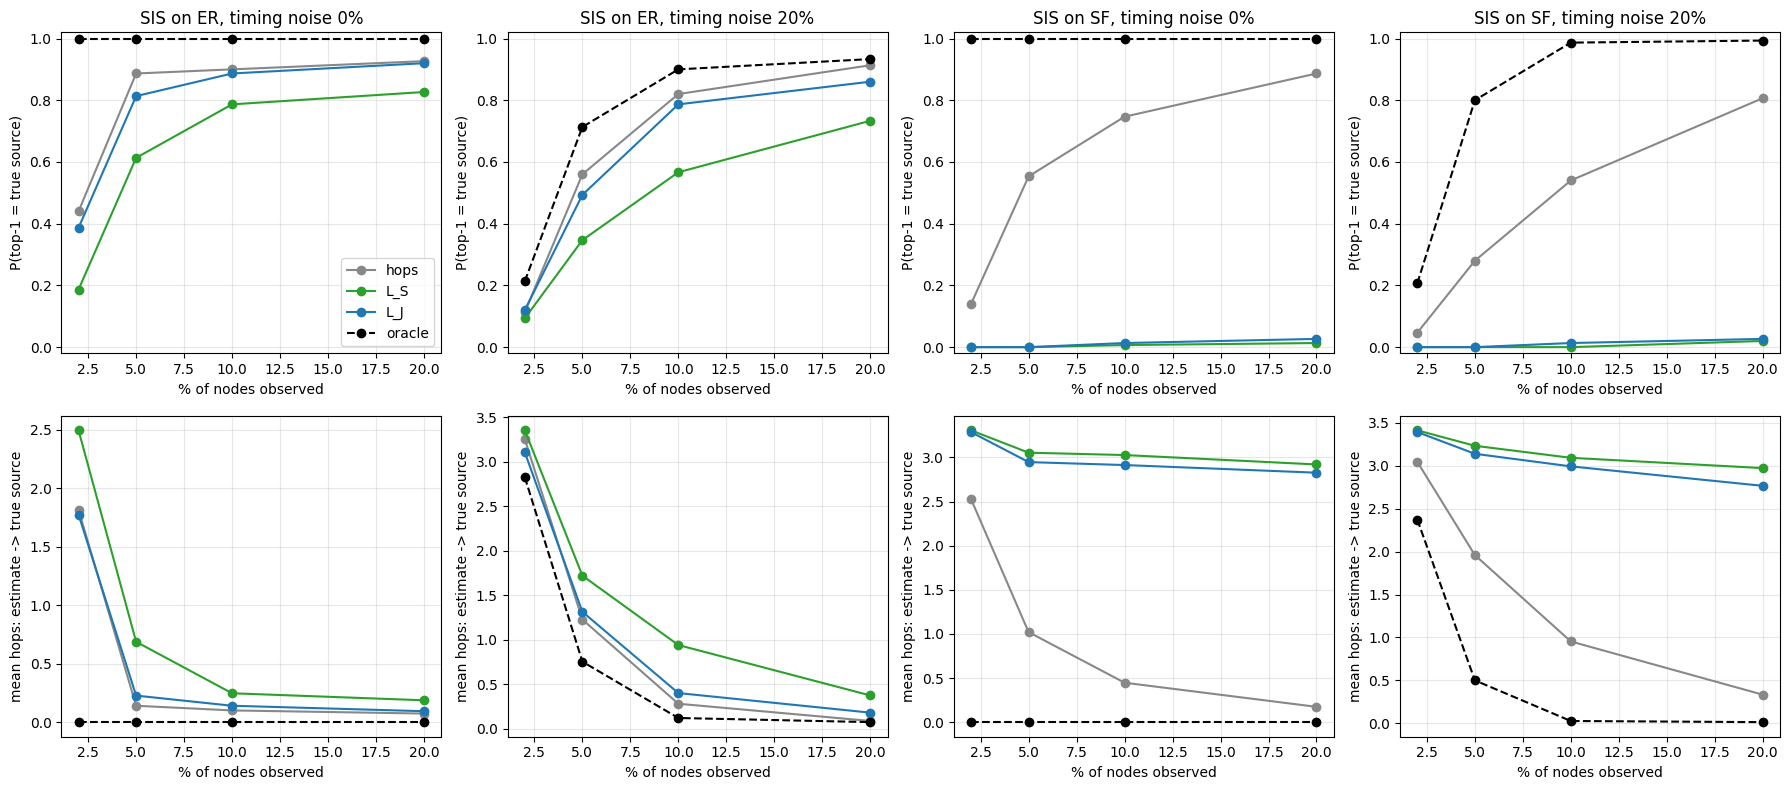

In [60]:
results_retro = {(name, nz): [run_retrodiction(name, f, nz) for f in obs_fracs]
                 for name in ['ER', 'SF'] for nz in noises}

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for col, (name, nz) in enumerate([(n_, z) for n_ in ['ER', 'SF'] for z in noises]):
  res = results_retro[(name, nz)]
  for k in preds:
    axes[0, col].plot(np.array(obs_fracs) * 100, [r[k]['top1'] for r in res],
                      marker='o', ls=pls[k], color=pcol[k], label=k)
    axes[1, col].plot(np.array(obs_fracs) * 100, [r[k]['err_hops'] for r in res],
                        marker='o', ls=pls[k], color=pcol[k], label=k)
  axes[0, col].set_title(f'SIS on {name}, timing noise {int(nz*100)}%')
  axes[0, col].set_ylabel('P(top-1 = true source)'); axes[0, col].set_ylim(-0.02, 1.02)
  axes[1, col].set_ylabel('mean hops: estimate -> true source')
  for r in (0, 1):
    axes[r, col].set_xlabel('% of nodes observed'); axes[r, col].grid(alpha=0.3)
axes[0, 0].legend()
plt.tight_layout(); plt.show()

In [61]:
print(f"{'net':3s} {'noise':>5s} {'obs%':>5s} | " + " | ".join(f"{k:>14s}" for k in preds))
for (name, nz), res in results_retro.items():
  for f, r in zip(obs_fracs, res):
    cells = " | ".join(f"{r[k]['top1']:.2f} ({r[k]['err_hops']:.2f}h)" for k in preds)
    print(f"{name:3s} {nz:5.1f} {int(f*100):5d} | {cells}")
print("cells: top-1 accuracy (mean hop error of the estimate)")


net noise  obs% |           hops |            L_S |            L_J |         oracle
ER    0.0     2 | 0.44 (1.81h) | 0.19 (2.49h) | 0.39 (1.77h) | 1.00 (0.00h)
ER    0.0     5 | 0.89 (0.14h) | 0.61 (0.69h) | 0.81 (0.23h) | 1.00 (0.00h)
ER    0.0    10 | 0.90 (0.10h) | 0.79 (0.25h) | 0.89 (0.14h) | 1.00 (0.00h)
ER    0.0    20 | 0.93 (0.07h) | 0.83 (0.19h) | 0.92 (0.09h) | 1.00 (0.00h)
ER    0.2     2 | 0.11 (3.25h) | 0.09 (3.35h) | 0.12 (3.11h) | 0.21 (2.83h)
ER    0.2     5 | 0.56 (1.23h) | 0.35 (1.72h) | 0.49 (1.31h) | 0.71 (0.75h)
ER    0.2    10 | 0.82 (0.28h) | 0.57 (0.94h) | 0.79 (0.40h) | 0.90 (0.12h)
ER    0.2    20 | 0.91 (0.09h) | 0.73 (0.37h) | 0.86 (0.18h) | 0.93 (0.07h)
SF    0.0     2 | 0.14 (2.53h) | 0.00 (3.31h) | 0.00 (3.29h) | 1.00 (0.00h)
SF    0.0     5 | 0.55 (1.02h) | 0.00 (3.05h) | 0.00 (2.95h) | 1.00 (0.00h)
SF    0.0    10 | 0.75 (0.45h) | 0.01 (3.03h) | 0.01 (2.91h) | 1.00 (0.00h)
SF    0.0    20 | 0.89 (0.17h) | 0.01 (2.92h) | 0.03 (2.83h) | 1.00 (0.00h)
SF  